In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

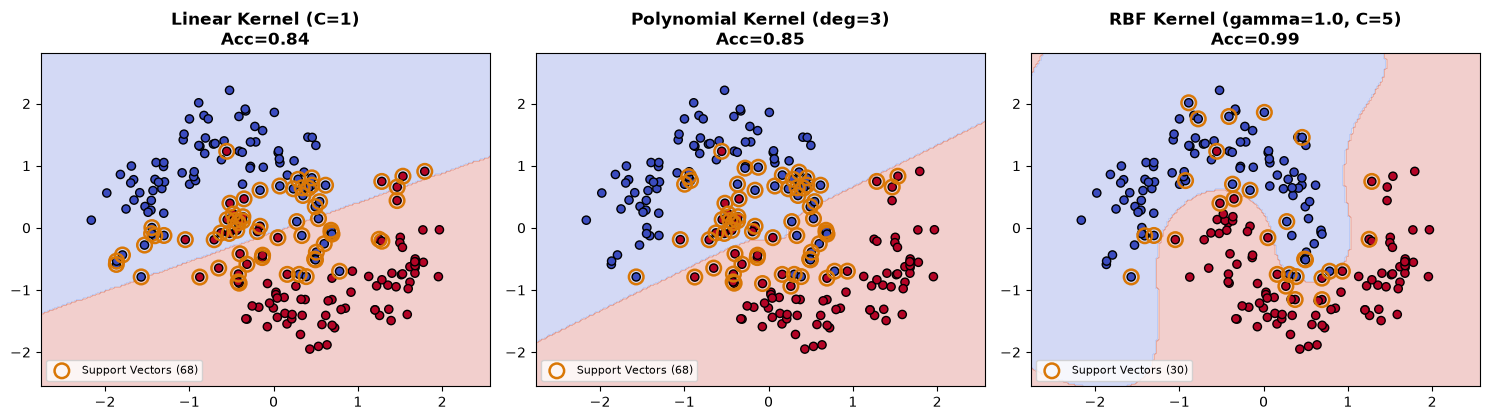

In [2]:
X_moon, y_moon = make_moons(n_samples=200, noise=0.18, random_state=42)
X_moon_sc = StandardScaler().fit_transform(X_moon)

kernels = [
    ('Linear Kernel (C=1)', SVC(kernel='linear', C=1.0)),
    ('Polynomial Kernel (deg=3)', SVC(kernel='poly', degree=3, C=1.0)),
    ('RBF Kernel (gamma=1.0, C=5)', SVC(kernel='rbf', gamma=1.0, C=5.0))
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
xx, yy = np.meshgrid(np.linspace(X_moon_sc[:,0].min()-0.6, X_moon_sc[:,0].max()+0.6, 200),
                     np.linspace(X_moon_sc[:,1].min()-0.6, X_moon_sc[:,1].max()+0.6, 200))

for ax, (title, clf) in zip(axes, kernels):
    clf.fit(X_moon_sc, y_moon)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')
    ax.scatter(X_moon_sc[:,0], X_moon_sc[:,1], c=y_moon, cmap='coolwarm', edgecolor='k', s=35)
    ax.scatter(clf.support_vectors_[:,0], clf.support_vectors_[:,1], s=110, facecolors='none',
               edgecolors='#D97706', linewidths=1.8, label=f'Support Vectors ({len(clf.support_vectors_)})')
    ax.set_title(f"{title}\nAcc={clf.score(X_moon_sc, y_moon):.2f}", fontweight='bold')
    ax.legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()

Best Hyperparameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV Accuracy: 0.9802
Test Accuracy: 0.9825

Classification Report:
               precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



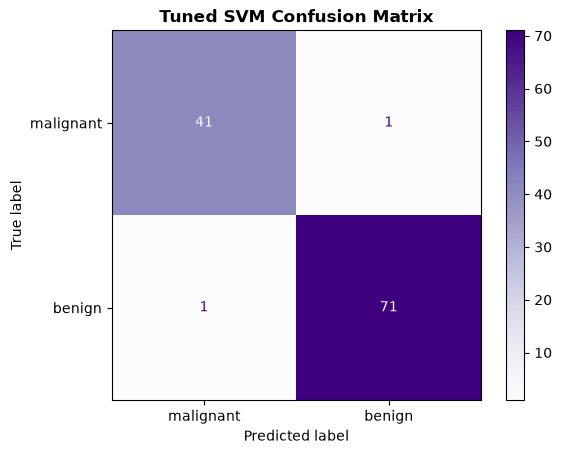

In [3]:
data = load_breast_cancer()
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=0.2, random_state=42, stratify=data.target)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_te_sc = scaler.transform(X_te)

param_grid = {
    'C': [0.1, 1, 10, 50],
    'gamma': ['scale', 0.01, 0.001],
    'kernel': ['linear', 'rbf']
}
grid = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_tr_sc, y_tr)

print("Best Hyperparameters:", grid.best_params_)
print(f"Best CV Accuracy: {grid.best_score_:.4f}")

best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_te_sc)
print(f"Test Accuracy: {accuracy_score(y_te, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_te, y_pred, target_names=data.target_names))

ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=data.target_names, cmap='Purples')
plt.title('Tuned SVM Confusion Matrix', fontweight='bold')
plt.show()